# Kepler — Interactive Newtonian Orbit Laboratory

Orbits are among the clearest demonstrations of how a simple physical law can generate rich behavior. The same inverse-square attraction can produce a circle, an ellipse, a near-collision, or an unbound flyby; the outcome is encoded entirely in the masses and initial state. This notebook turns that idea into an experiment: first we develop the model, then we inspect a reproducible reference orbit, and finally we change the system interactively.

The goals are to connect Newton's law to observable trajectories, distinguish bound motion from escape and collision, and use conservation of energy and angular momentum to assess both the physics and the numerical calculation. The implementation uses structured Python functions, NumPy arrays, pandas tables, a velocity-Verlet integrator, Plotly, Matplotlib, and Jupyter widgets.

> **GitHub note:** GitHub renders this notebook as a static document. Clone it and run it in JupyterLab to activate the controls and animation.

## 1. From Newton's law to the two-body problem

Consider two bodies with masses $m_1$ and $m_2$, positions $\mathbf r_1$ and $\mathbf r_2$, and velocities $\mathbf v_1$ and $\mathbf v_2$. Newtonian gravity assigns the force

$$\mathbf F_{12}=G\frac{m_1m_2}{|\mathbf r_2-\mathbf r_1|^3}(\mathbf r_2-\mathbf r_1), \qquad \mathbf F_{21}=-\mathbf F_{12}.$$

Using $\mathbf F=m\mathbf a$ gives the coupled equations of motion:

For bodies at $\mathbf r_1$ and $\mathbf r_2$, the accelerations are

$$\mathbf a_1 = Gm_2\frac{\mathbf r_2-\mathbf r_1}{|\mathbf r_2-\mathbf r_1|^3}, \qquad \mathbf a_2 = Gm_1\frac{\mathbf r_1-\mathbf r_2}{|\mathbf r_2-\mathbf r_1|^3}.$$

The center of mass,

$$\mathbf R=\frac{m_1\mathbf r_1+m_2\mathbf r_2}{m_1+m_2},$$

moves at constant velocity when no external force acts. Introducing the relative coordinate $\mathbf r=\mathbf r_2-\mathbf r_1$ reduces the coupled system to

$$\ddot{\mathbf r}=-G(m_1+m_2)\frac{\mathbf r}{|\mathbf r|^3}.$$

This is the mathematical core of the Kepler problem. In the exact two-body model, a non-colliding trajectory is a conic section with the center of mass at a focus.

### Energy, angular momentum, and orbit type

The total mechanical energy and planar angular momentum are

$$E=\frac12m_1|\mathbf v_1|^2+\frac12m_2|\mathbf v_2|^2-\frac{Gm_1m_2}{|\mathbf r_2-\mathbf r_1|},$$

$$L_z=m_1(x_1v_{1y}-y_1v_{1x})+m_2(x_2v_{2y}-y_2v_{2x}).$$

Both should remain constant. The relative specific orbital energy

$$\varepsilon=\frac12|\mathbf v_2-\mathbf v_1|^2-\frac{G(m_1+m_2)}{|\mathbf r_2-\mathbf r_1|}$$

provides a compact classification: $\varepsilon<0$ is bound (elliptical, including circular), $\varepsilon=0$ is the parabolic escape threshold, and $\varepsilon>0$ is hyperbolic and unbound. A collision is declared when the separation becomes smaller than the sum of the chosen body radii.

### Assumptions and units

We treat each object as a spherical point mass outside a collision radius, restrict motion to a plane, and neglect relativity, tides, rotation, mass loss, drag, and all other bodies. The presets use normalized units with $G=1$. Any consistent system of units works if its matching value of $G$ is entered.

In [1]:
from pathlib import Path
import sys

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, clear_output, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.orbit import (PRESETS, conservation_summary, diagnostics_figure,
                       export_results, get_preset, simulate,
                       to_dataframe, trajectory_figure)

print(f'Project root: {PROJECT_ROOT}')
print(f'Available scenarios: {len(PRESETS)}')

Project root: /home/MLee/projects/Kepler
Available scenarios: 5


## 2. Numerical method

Except for special analytic solutions, a simulator advances the state in finite time increments $\Delta t$. This notebook uses **velocity Verlet**, a second-order symplectic method. Given position $\mathbf r_n$, velocity $\mathbf v_n$, and acceleration $\mathbf a_n$, it applies

$$\mathbf r_{n+1}=\mathbf r_n+\mathbf v_n\Delta t+\frac12\mathbf a_n\Delta t^2,$$

$$\mathbf v_{n+1}=\mathbf v_n+\frac12(\mathbf a_n+\mathbf a_{n+1})\Delta t.$$

Symplectic methods respect the geometry of Hamiltonian motion and usually keep orbital energy bounded much better than forward Euler. They are not exact: close encounters create large accelerations, so reducing `dt` remains essential. The diagnostic plots below make numerical drift visible rather than hiding it.

## 3. Reference experiment: a stable circular binary

We begin with two equal masses separated by one distance unit. Each is placed half a unit from the barycenter and given the tangential speed $1/\sqrt{2}$. Their gravitational attraction supplies the centripetal acceleration, so both bodies should trace circles around the stationary center of mass. This cell is deliberately non-interactive: its saved output remains visible when the notebook is viewed on GitHub.

Classification: Bound orbit
Samples: 2,401
Separation range: 1.00000000 to 1.00002499
Maximum relative energy error: 6.248e-10
Maximum relative angular-momentum error: 2.669e-15


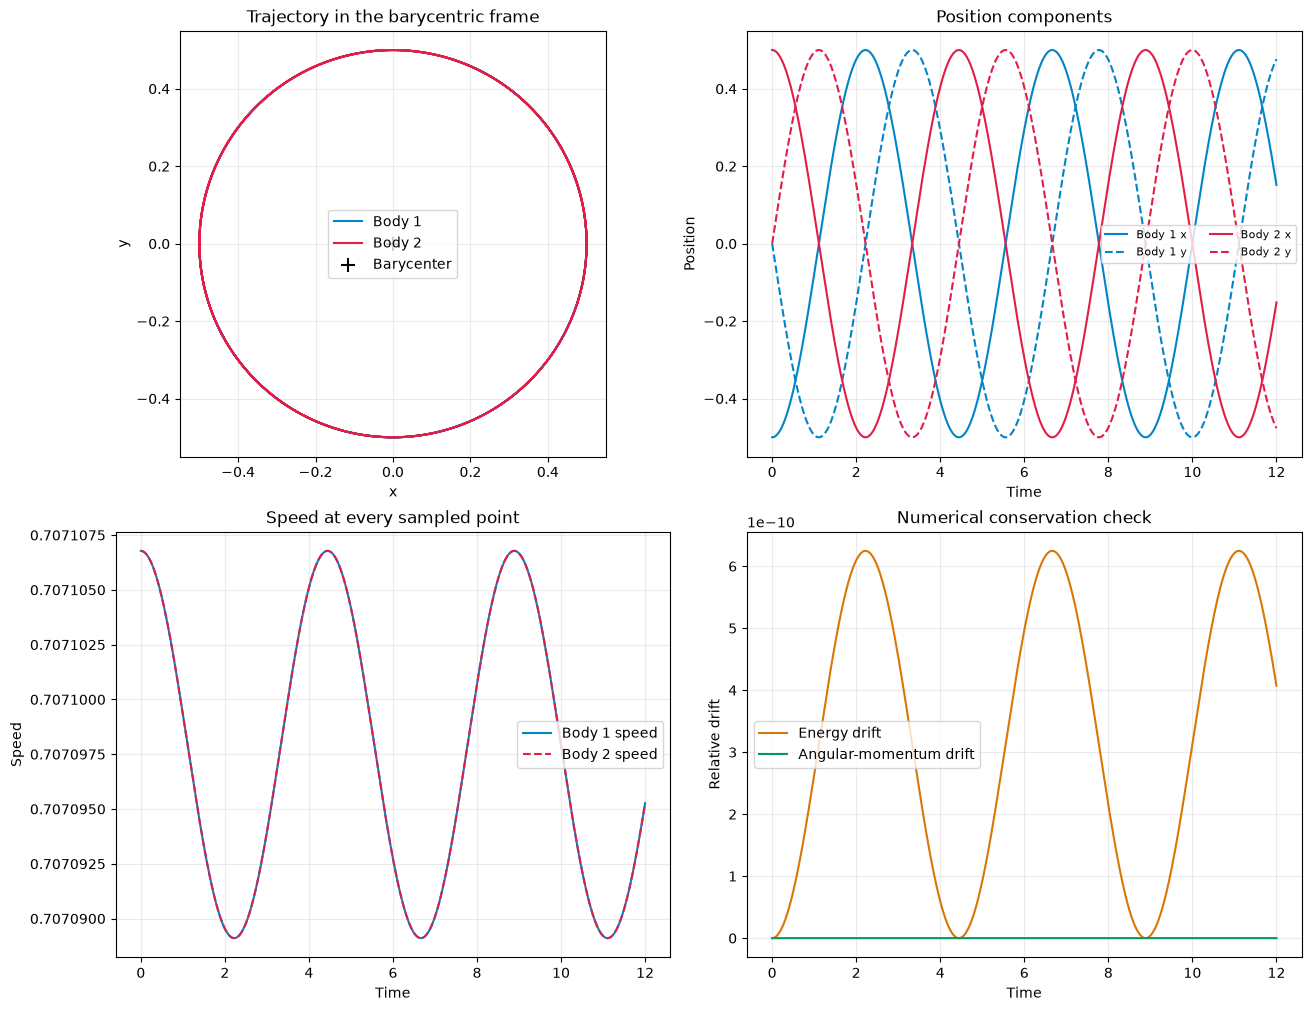

,time,body1_x,body1_y,body2_x,body2_y,body1_vx,body1_vy,body2_vx,body2_vy,body1_speed,body2_speed,separation,kinetic_energy,potential_energy,total_energy,angular_momentum
0,0.0,-0.500000,0.000000,0.500000,0.000000,0.000000,-0.707107,0.000000,0.707107,0.707107,0.707107,1.000000,0.500000,-1.000000,-0.5,0.707107
1200,6.0,0.295054,-0.403674,-0.295054,0.403674,0.570863,0.417247,-0.570863,-0.417247,0.707093,0.707093,1.000020,0.499980,-0.999980,-0.5,0.707107
2400,12.0,0.151819,0.476402,-0.151819,-0.476402,-0.673715,0.214689,0.673715,-0.214689,0.707095,0.707095,1.000016,0.499984,-0.999984,-0.5,0.707107


In [2]:
reference = simulate(get_preset('Stable circular binary'))
reference_summary = conservation_summary(reference)
reference_table = to_dataframe(reference)

print(f"Classification: {reference_summary['classification']}")
print(f"Samples: {reference_summary['samples']:,}")
print(f"Separation range: {reference_summary['minimum_separation']:.8f} to {reference_summary['maximum_separation']:.8f}")
print(f"Maximum relative energy error: {reference_summary['max_relative_energy_error']:.3e}")
print(f"Maximum relative angular-momentum error: {reference_summary['max_relative_angular_momentum_error']:.3e}")

figure, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)
axis = axes[0, 0]
axis.plot(reference['r1'][:, 0], reference['r1'][:, 1], label='Body 1', color='#0284c7')
axis.plot(reference['r2'][:, 0], reference['r2'][:, 1], label='Body 2', color='#e11d48')
axis.scatter([0], [0], marker='+', s=100, color='black', label='Barycenter')
axis.set(title='Trajectory in the barycentric frame', xlabel='x', ylabel='y', aspect='equal')
axis.legend(); axis.grid(alpha=0.25)

axis = axes[0, 1]
axis.plot(reference['time'], reference['r1'][:, 0], label='Body 1 x', color='#0284c7')
axis.plot(reference['time'], reference['r1'][:, 1], label='Body 1 y', color='#0284c7', linestyle='--')
axis.plot(reference['time'], reference['r2'][:, 0], label='Body 2 x', color='#e11d48')
axis.plot(reference['time'], reference['r2'][:, 1], label='Body 2 y', color='#e11d48', linestyle='--')
axis.set(title='Position components', xlabel='Time', ylabel='Position')
axis.legend(ncols=2, fontsize=8); axis.grid(alpha=0.25)

axis = axes[1, 0]
axis.plot(reference['time'], reference['speed1'], label='Body 1 speed', color='#0284c7')
axis.plot(reference['time'], reference['speed2'], label='Body 2 speed', color='#e11d48', linestyle='--')
axis.set(title='Speed at every sampled point', xlabel='Time', ylabel='Speed')
axis.legend(); axis.grid(alpha=0.25)

axis = axes[1, 1]
energy0 = reference['total_energy'][0]
angular0 = reference['angular_momentum'][0]
axis.plot(reference['time'], (reference['total_energy'] - energy0) / abs(energy0), label='Energy drift', color='#d97706')
axis.plot(reference['time'], (reference['angular_momentum'] - angular0) / abs(angular0), label='Angular-momentum drift', color='#059669')
axis.set(title='Numerical conservation check', xlabel='Time', ylabel='Relative drift')
axis.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
axis.legend(); axis.grid(alpha=0.25)
plt.show()

reference_table.iloc[[0, len(reference_table) // 2, -1]]

### Reading the reference result

The two circles have equal radii and remain on opposite sides of the barycenter, as symmetry requires. The sinusoidal position components differ by half a period, while both speed magnitudes remain essentially constant. Most importantly, the conservation errors stay extremely small and oscillatory rather than growing monotonically. That behavior is characteristic of a well-resolved symplectic integration and supports the interpretation of the trajectory as a stable numerical orbit.

## 4. Interactive laboratory

Choose a saved scenario first, then edit any value. **Load preset** restores the selected scenario, **Run simulation** calculates and displays it, and **Export results** saves the latest run under `exports/`.

In [3]:
style = {'description_width': '115px'}
wide = widgets.Layout(width='260px')
short = widgets.Layout(width='235px')

preset = widgets.Dropdown(options=list(PRESETS), description='Scenario', style=style, layout=widgets.Layout(width='420px'))
description = widgets.HTML()
m1 = widgets.FloatText(description='Mass 1', style=style, layout=short)
m2 = widgets.FloatText(description='Mass 2', style=style, layout=short)
radius1 = widgets.FloatText(description='Radius 1', style=style, layout=short)
radius2 = widgets.FloatText(description='Radius 2', style=style, layout=short)
G = widgets.FloatText(description='G', style=style, layout=short)
dt = widgets.FloatText(description='Time step', style=style, layout=short)
duration = widgets.FloatText(description='Duration', style=style, layout=short)
r1x = widgets.FloatText(description='Body 1 x', style=style, layout=short)
r1y = widgets.FloatText(description='Body 1 y', style=style, layout=short)
r2x = widgets.FloatText(description='Body 2 x', style=style, layout=short)
r2y = widgets.FloatText(description='Body 2 y', style=style, layout=short)
v1x = widgets.FloatText(description='Body 1 vx', style=style, layout=short)
v1y = widgets.FloatText(description='Body 1 vy', style=style, layout=short)
v2x = widgets.FloatText(description='Body 2 vx', style=style, layout=short)
v2y = widgets.FloatText(description='Body 2 vy', style=style, layout=short)

load_button = widgets.Button(description='Load preset', icon='refresh', button_style='info')
run_button = widgets.Button(description='Run simulation', icon='play', button_style='success')
export_button = widgets.Button(description='Export results', icon='download', button_style='warning', disabled=True)
status = widgets.HTML()
output = widgets.Output()
latest = {'result': None}

def load_selected(_=None):
    config = get_preset(preset.value)
    m1.value, m2.value = config['m1'], config['m2']
    radius1.value, radius2.value = config['radius1'], config['radius2']
    G.value, dt.value, duration.value = config['G'], config['dt'], config['duration']
    r1x.value, r1y.value = config['r1']
    r2x.value, r2y.value = config['r2']
    v1x.value, v1y.value = config['v1']
    v2x.value, v2y.value = config['v2']
    description.value = f"<i>{config['description']}</i>"
    status.value = '<span style="color:#64748b">Preset loaded. Press Run simulation.</span>'

def current_config():
    return {'description': description.value, 'm1': m1.value, 'm2': m2.value,
            'radius1': radius1.value, 'radius2': radius2.value, 'G': G.value,
            'dt': dt.value, 'duration': duration.value,
            'r1': [r1x.value, r1y.value], 'r2': [r2x.value, r2y.value],
            'v1': [v1x.value, v1y.value], 'v2': [v2x.value, v2y.value]}

def run_simulation(_=None):
    run_button.disabled = True
    export_button.disabled = True
    status.value = '<b>Calculating…</b>'
    try:
        result = simulate(current_config())
        latest['result'] = result
        summary = conservation_summary(result)
        with output:
            clear_output(wait=True)
            display(HTML(
                f"<h3>{summary['classification']}</h3>"
                f"<b>Samples:</b> {summary['samples']:,} &nbsp; "
                f"<b>Final time:</b> {summary['simulated_time']:.6g} &nbsp; "
                f"<b>Minimum separation:</b> {summary['minimum_separation']:.6g}<br>"
                f"<b>Maximum relative energy error:</b> {summary['max_relative_energy_error']:.3e} &nbsp; "
                f"<b>Maximum relative angular momentum error:</b> {summary['max_relative_angular_momentum_error']:.3e}"))
            display(trajectory_figure(result, animated=True))
            display(diagnostics_figure(result))
            display(HTML('<h3>First and last data samples</h3>'))
            display(to_dataframe(result).iloc[[0, -1]])
        status.value = '<span style="color:#16a34a"><b>Simulation complete.</b></span>'
        export_button.disabled = False
    except Exception as error:
        status.value = f'<span style="color:#dc2626"><b>Error:</b> {error}</span>'
    finally:
        run_button.disabled = False

def export_simulation(_=None):
    if latest['result'] is None:
        return
    export_button.disabled = True
    status.value = '<b>Exporting…</b>'
    files = export_results(latest['result'], PROJECT_ROOT / 'exports')
    links = []
    notes = []
    for label, path in files.items():
        if label.endswith('_note'):
            notes.append(str(path))
        else:
            relative = Path(path).relative_to(PROJECT_ROOT)
            links.append(f'<li><code>{relative}</code></li>')
    status.value = '<span style="color:#16a34a"><b>Export complete:</b></span><ul>' + ''.join(links) + '</ul>' + '<br>'.join(notes)
    export_button.disabled = False

load_button.on_click(load_selected)
run_button.on_click(run_simulation)
export_button.on_click(export_simulation)
preset.observe(lambda change: load_selected() if change['name'] == 'value' else None, names='value')
load_selected()

initial_conditions = widgets.VBox([
    widgets.HTML('<b>Positions</b>'), widgets.HBox([r1x, r1y]), widgets.HBox([r2x, r2y]),
    widgets.HTML('<b>Velocities</b>'), widgets.HBox([v1x, v1y]), widgets.HBox([v2x, v2y])])
physical_settings = widgets.VBox([
    widgets.HTML('<b>Physical and numerical settings</b>'), widgets.HBox([m1, m2]),
    widgets.HBox([radius1, radius2]), widgets.HBox([G, dt]), duration])
controls = widgets.VBox([preset, description, widgets.HBox([initial_conditions, physical_settings]),
                         widgets.HBox([load_button, run_button, export_button]), status])
display(controls, output)

Output()

## Interpreting the results

- **Bound orbit:** negative relative specific orbital energy.
- **Escape / unbound:** positive energy and outward radial motion at the end.
- **Marginal escape:** relative specific energy is approximately zero.
- **Collision:** separation reached the sum of the configured radii.
- The conservation curves should remain close to zero. A large drift means the time step should be reduced.

The classification describes the simulated terminal state; it is not a general proof of long-term stability.